# Ekstrak dan Muat Dataset PlanetLab

Dataset berisi trace dari beberapa hari. Notebook ini mengekstrak seluruh folder harian, lalu membandingkan distribusi CPU setiap tanggal. `20110303` tetap digunakan untuk analisis lanjutan yang saat ini hanya mengolah satu hari.

In [1]:
!pip install pandas numpy matplotlib seaborn requests tqdm

from pathlib import Path, PurePosixPath
import re
import requests
import zipfile

# ==========================================
# CONFIGURATION
# ==========================================

DATA_URL = (
    "https://codeload.github.com/"
    "beloglazov/planetlab-workload-traces/zip/refs/heads/master"
)

DATA_DIR = Path("data/planetlab")
SELECTED_DAY = "20110420"

DATA_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# DOWNLOAD
# ==========================================

zip_path = DATA_DIR / "planetlab_traces.zip"

if not zip_path.exists():
    print("Downloading PlanetLab dataset...")
    response = requests.get(DATA_URL, timeout=180)
    response.raise_for_status()
    zip_path.write_bytes(response.content)
    print("Download completed.")
else:
    print("Dataset ZIP already exists.")

# ==========================================
# EXTRACT ALL DAILY TRACES
# ==========================================

with zipfile.ZipFile(zip_path, "r") as zf:
    daily_members = {}

    for member in zf.namelist():
        if member.endswith("/"):
            continue

        parts = PurePosixPath(member).parts
        day_index = next(
            (i for i, part in enumerate(parts) if re.fullmatch(r"\d{8}", part)),
            None,
        )
        if day_index is None or day_index + 1 >= len(parts):
            continue

        day = parts[day_index]
        relative_path = parts[day_index + 1:]
        daily_members.setdefault(day, []).append((member, relative_path))

    if not daily_members:
        raise FileNotFoundError("No daily trace folders (YYYYMMDD) found in the archive.")

    available_days = sorted(daily_members)

    for day in available_days:
        day_dir = DATA_DIR / day
        for member, relative_path in daily_members[day]:
            output_path = day_dir.joinpath(*relative_path)
            output_path.parent.mkdir(parents=True, exist_ok=True)
            output_path.write_bytes(zf.read(member))

print(f"Extracted {len(available_days)} daily folders: {', '.join(available_days)}")
print("Dataset location:", DATA_DIR.resolve())

Defaulting to user installation because normal site-packages is not writeable
Dataset ZIP already exists.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Extracted 10 daily folders: 20110303, 20110306, 20110309, 20110322, 20110325, 20110403, 20110409, 20110411, 20110412, 20110420
Dataset location: E:\.TEMPORARY\Project STMH\data\planetlab


In [14]:
import numpy as np
import pandas as pd

from pathlib import Path

# ==========================================
# LOAD PLANETLAB TRACES
# ==========================================

def load_planetlab_day(folder, day):
    folder = Path(folder)
    vm_traces = {}

    for file_path in sorted(folder.rglob("*")):
        if not file_path.is_file():
            continue

        try:
            values = np.loadtxt(file_path, dtype=float)
            values = np.asarray(values).flatten()

            if len(values) == 0 or not np.all(np.isfinite(values)):
                continue

            vm_traces[file_path.name] = values
        except (ValueError, OSError):
            continue

    if not vm_traces:
        raise ValueError(f"No valid VM trace files were found for {day}.")

    lengths = pd.Series({vm: len(values) for vm, values in vm_traces.items()})
    max_length = int(lengths.max())

    workload = pd.DataFrame({
        vm: np.pad(values, (0, max_length - len(values)), constant_values=np.nan)
        for vm, values in vm_traces.items()
    })

    start_time = pd.Timestamp(
        year=int(day[:4]), month=int(day[4:6]), day=int(day[6:8])
    )
    workload.index = pd.date_range(start=start_time, periods=max_length, freq="5min")
    workload.index.name = "timestamp"

    print(f"{day}: {len(vm_traces)} VM traces, shape {workload.shape}")
    return workload


# Muat semua hari; df tetap menunjuk ke hari pilihan untuk sel analisis berikutnya.
df_by_day = {
    day: load_planetlab_day(DATA_DIR / day, day)
    for day in available_days
}

if SELECTED_DAY not in df_by_day:
    raise ValueError(f"Selected day {SELECTED_DAY} was not found in the archive.")

df = df_by_day[SELECTED_DAY]
print("\nSelected-day dataset shape:", df.shape)
display(df.head())

20110303: 1052 VM traces, shape (288, 1052)
20110306: 898 VM traces, shape (288, 898)
20110309: 1061 VM traces, shape (288, 1061)
20110322: 1516 VM traces, shape (288, 1516)
20110325: 1078 VM traces, shape (288, 1078)
20110403: 1463 VM traces, shape (288, 1463)
20110409: 1358 VM traces, shape (288, 1358)
20110411: 1233 VM traces, shape (288, 1233)
20110412: 1054 VM traces, shape (288, 1054)
20110420: 1033 VM traces, shape (288, 1033)

Selected-day dataset shape: (288, 1033)


,146-179_surfsnel_dsl_internl_net_arizona_beta,146-179_surfsnel_dsl_internl_net_arizona_nest,146-179_surfsnel_dsl_internl_net_howard_p2psip,146-179_surfsnel_dsl_internl_net_root,146-179_surfsnel_dsl_internl_net_tsinghua_xyz,146-179_surfsnel_dsl_internl_net_uw_oneswarm,147-179_surfsnel_dsl_internl_net_arizona_beta,147-179_surfsnel_dsl_internl_net_arizona_nest,147-179_surfsnel_dsl_internl_net_arizona_owl,147-179_surfsnel_dsl_internl_net_irisaple_HEAP,...,ttu1-1_nodes_planet-lab_org_google_highground,ttu1-1_nodes_planet-lab_org_irisaple_wup,ttu1-1_nodes_planet-lab_org_uw_oneswarm,ttu2-1_nodes_planet-lab_org_irisaple_wup,ttu2-1_nodes_planet-lab_org_uw_oneswarm,venus_silicon-valley_ru_irisaple_HEAP,venus_silicon-valley_ru_irisaple_wup,venus_silicon-valley_ru_uw_oneswarm,vn4_cse_wustl_edu_nyu_d,vn4_cse_wustl_edu_princeton_codeen
timestamp,,,,,,,,,,,,,,,,,,,,,
2011-04-20 00:00:00,18.0,17.0,15.0,37.0,6.0,0.0,21.0,4.0,23.0,5.0,...,10.0,6.0,6.0,2.0,4.0,4.0,6.0,0.0,0.0,4.0
2011-04-20 00:05:00,0.0,22.0,16.0,53.0,14.0,0.0,0.0,0.0,0.0,5.0,...,0.0,4.0,6.0,2.0,10.0,2.0,6.0,4.0,2.0,8.0
2011-04-20 00:10:00,0.0,20.0,21.0,32.0,17.0,0.0,18.0,18.0,12.0,4.0,...,12.0,4.0,2.0,6.0,62.0,4.0,19.0,0.0,0.0,4.0
2011-04-20 00:15:00,17.0,3.0,22.0,36.0,6.0,0.0,2.0,13.0,12.0,5.0,...,0.0,4.0,13.0,0.0,4.0,0.0,4.0,0.0,0.0,6.0
2011-04-20 00:20:00,0.0,17.0,3.0,26.0,4.0,0.0,0.0,0.0,0.0,5.0,...,0.0,2.0,36.0,2.0,2.0,2.0,6.0,0.0,0.0,8.0


Datanya punya 1033 virtual machine! dengan 288 baris data.

In [3]:
# ==========================================
# BASIC DATA INSPECTION
# ==========================================

print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes.value_counts())

print("\nBasic statistics:")
display(df.describe().T.head(10))

print("\nMissing values:")
print("Total missing:", df.isna().sum().sum())

print("\nMinimum CPU value:", df.min().min())
print("Maximum CPU value:", df.max().max())

print("\nNumber of duplicated timestamps:",
      df.index.duplicated().sum())

Dataset shape: (288, 1033)

Data types:
float64    1033
Name: count, dtype: int64

Basic statistics:


,count,mean,std,min,25%,50%,75%,max
146-179_surfsnel_dsl_internl_net_arizona_beta,288.0,9.118056,11.944119,0.0,0.0,0.5,17.00,57.0
146-179_surfsnel_dsl_internl_net_arizona_nest,288.0,10.590278,12.767780,0.0,0.0,1.0,19.00,60.0
146-179_surfsnel_dsl_internl_net_howard_p2psip,288.0,9.916667,11.187661,0.0,0.0,4.5,18.00,63.0
146-179_surfsnel_dsl_internl_net_root,288.0,26.798611,16.038316,1.0,17.0,26.0,35.00,90.0
146-179_surfsnel_dsl_internl_net_tsinghua_xyz,288.0,11.638889,6.298179,2.0,6.0,11.0,16.00,39.0
146-179_surfsnel_dsl_internl_net_uw_oneswarm,288.0,22.482639,15.313440,0.0,13.0,21.0,30.25,81.0
147-179_surfsnel_dsl_internl_net_arizona_beta,288.0,13.850694,11.772018,0.0,0.0,15.0,21.25,52.0
147-179_surfsnel_dsl_internl_net_arizona_nest,288.0,9.875000,11.540491,0.0,0.0,3.0,19.00,57.0
147-179_surfsnel_dsl_internl_net_arizona_owl,288.0,12.729167,11.509559,0.0,0.0,14.0,22.00,51.0
147-179_surfsnel_dsl_internl_net_irisaple_HEAP,288.0,7.093750,2.565157,1.0,5.0,7.0,8.00,16.0



Missing values:
Total missing: 0

Minimum CPU value: 0.0
Maximum CPU value: 99.0

Number of duplicated timestamps: 0


In [4]:
# ==========================================
# CPU UTILIZATION SCALE CHECK
# ==========================================

for day, daily_df in df_by_day.items():
    max_value = daily_df.max().max()

    if max_value <= 1.5:
        print(f"{day}: CPU values appear to use 0-1 scale.")
    elif max_value <= 100.5:
        print(f"{day}: converting CPU values from percentage to 0-1 scale.")
        df_by_day[day] = daily_df / 100.0
    else:
        raise ValueError(
            f"Unexpected CPU utilization scale for {day}. "
            "Inspect the raw dataset before proceeding."
        )

df = df_by_day[SELECTED_DAY]

# Check that the selected dataset is now on a 0-1 scale.
print("Selected-day maximum CPU value:", df.max().max())

20110303: converting CPU values from percentage to 0-1 scale.
20110306: converting CPU values from percentage to 0-1 scale.
20110309: converting CPU values from percentage to 0-1 scale.
20110322: converting CPU values from percentage to 0-1 scale.
20110325: converting CPU values from percentage to 0-1 scale.
20110403: converting CPU values from percentage to 0-1 scale.
20110409: converting CPU values from percentage to 0-1 scale.
20110411: converting CPU values from percentage to 0-1 scale.
20110412: converting CPU values from percentage to 0-1 scale.
20110420: converting CPU values from percentage to 0-1 scale.
Selected-day maximum CPU value: 0.99


In [5]:
# ==========================================
# SELECT COMPLETE VM TRACES
# ==========================================

complete_vm_columns = df.columns[
    df.notna().all(axis=0)
]

df_complete = df[complete_vm_columns].copy()

print("Original VM count:", df.shape[1])
print("Complete VM count:", df_complete.shape[1])

print("Complete dataset shape:", df_complete.shape)

Original VM count: 1033
Complete VM count: 1033
Complete dataset shape: (288, 1033)


# EDA

### CPU Utilization Distribution

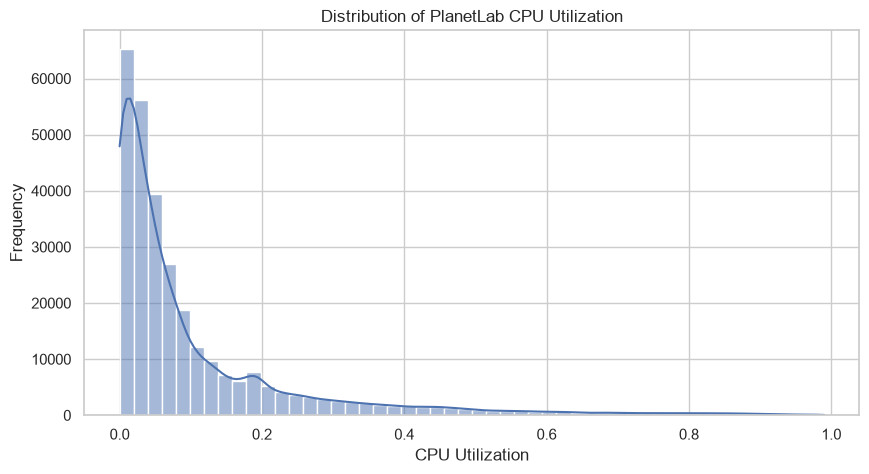

,mean,median,std,min,max,p95
planetlab1_s3_kth_se_tauple_planet_39,0.864861,0.870,0.103372,0.48,0.99,0.9800
planetlab1-buenosaires_lan_redclara_net_purdue_2,0.850104,0.870,0.097429,0.37,0.98,0.9465
planetlab-node3_it-sudparis_eu_cambridge_spe24,0.796250,0.820,0.106296,0.40,0.95,0.9100
planet1_scs_cs_nyu_edu_colostate_557,0.774792,0.810,0.129647,0.30,0.94,0.9000
planetlab2_s3_kth_se_tauple_planet_39,0.766528,0.780,0.114337,0.30,0.98,0.9300
planetlab4_mini_pw_edu_pl_waseda_ow,0.753021,0.810,0.147032,0.28,0.99,0.9000
peeramide_irisa_fr_ethzcs_tracegatherer,0.676389,0.755,0.195466,0.22,0.92,0.8900
planetlab-5_eecs_cwru_edu_princeton_codeen,0.600729,0.610,0.039867,0.36,0.69,0.6400
planetlab4_mini_pw_edu_pl_purdue_2,0.592882,0.640,0.138520,0.15,0.85,0.7700
planetlab2_s3_kth_se_sics_peerialism,0.565486,0.695,0.298768,0.00,0.92,0.8700


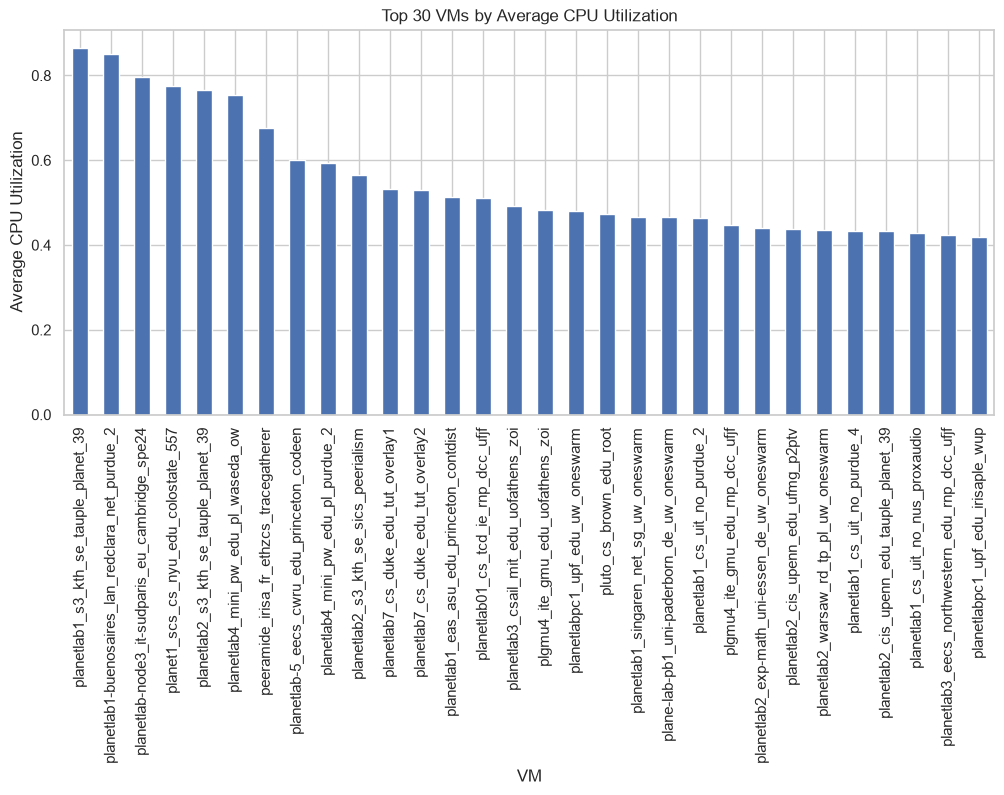

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Flatten all VM observations
cpu_values = df_complete.to_numpy().flatten()
cpu_values = cpu_values[~np.isnan(cpu_values)]

plt.figure(figsize=(10, 5))

sns.histplot(
    cpu_values,
    bins=50,
    kde=True
)

plt.title("Distribution of PlanetLab CPU Utilization")
plt.xlabel("CPU Utilization")
plt.ylabel("Frequency")

plt.show()

# ==========================================
# PER-VM STATISTICS
# ==========================================

vm_stats = pd.DataFrame({
    "mean": df_complete.mean(),
    "median": df_complete.median(),
    "std": df_complete.std(),
    "min": df_complete.min(),
    "max": df_complete.max(),
    "p95": df_complete.quantile(0.95)
})

vm_stats = vm_stats.sort_values(
    "mean",
    ascending=False
)

display(vm_stats.head(20))

# ==========================================
# AVERAGE CPU UTILIZATION PER VM
# ==========================================
plt.figure(figsize=(12, 5))

vm_stats["mean"].sort_values(
    ascending=False
).head(30).plot(kind="bar")

plt.title("Top 30 VMs by Average CPU Utilization")
plt.xlabel("VM")
plt.ylabel("Average CPU Utilization")
plt.xticks(rotation=90)

plt.show()

- Apakah mayoritas CPU utilization berada di bawah 20%?
- Apakah ada banyak VM dengan penggunaan CPU tinggi?
- Apakah distribusinya memiliki ekor panjang (right-skewed)?
- Apakah ada nilai yang mendekati atau melebihi 100%?
  
Distribusi workload didominasi penggunaan CPU rendah dapat memberikan peluang consolidation. 
Namun juga terdapat workload yang pernah melebihi 80%

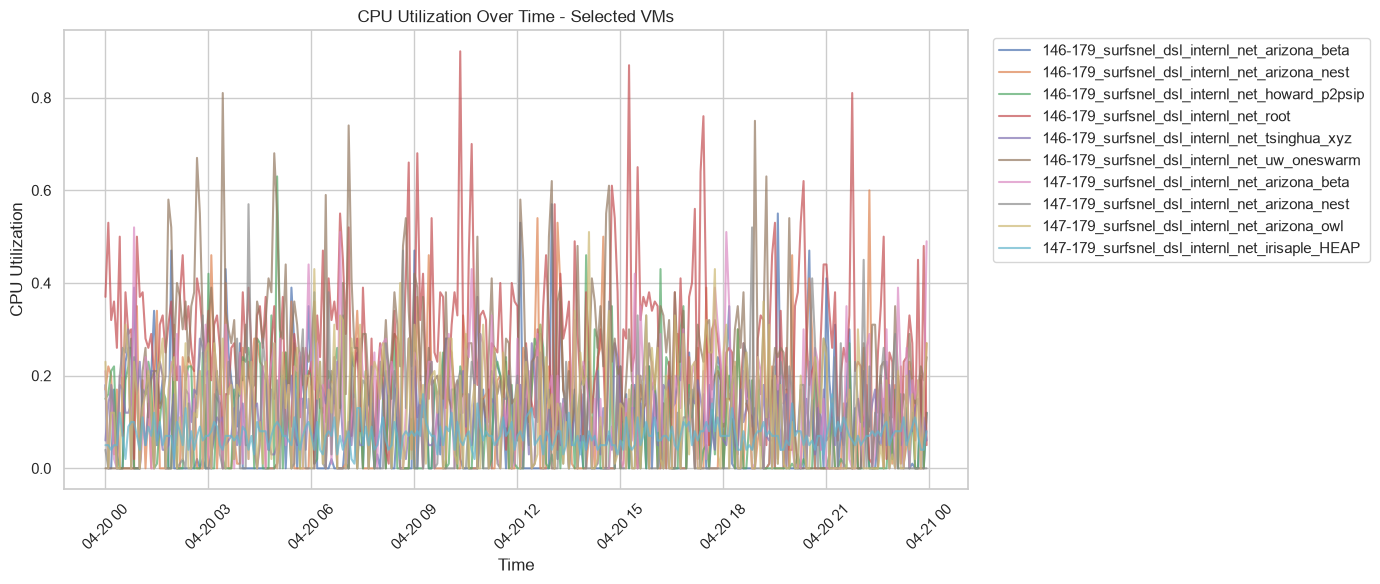

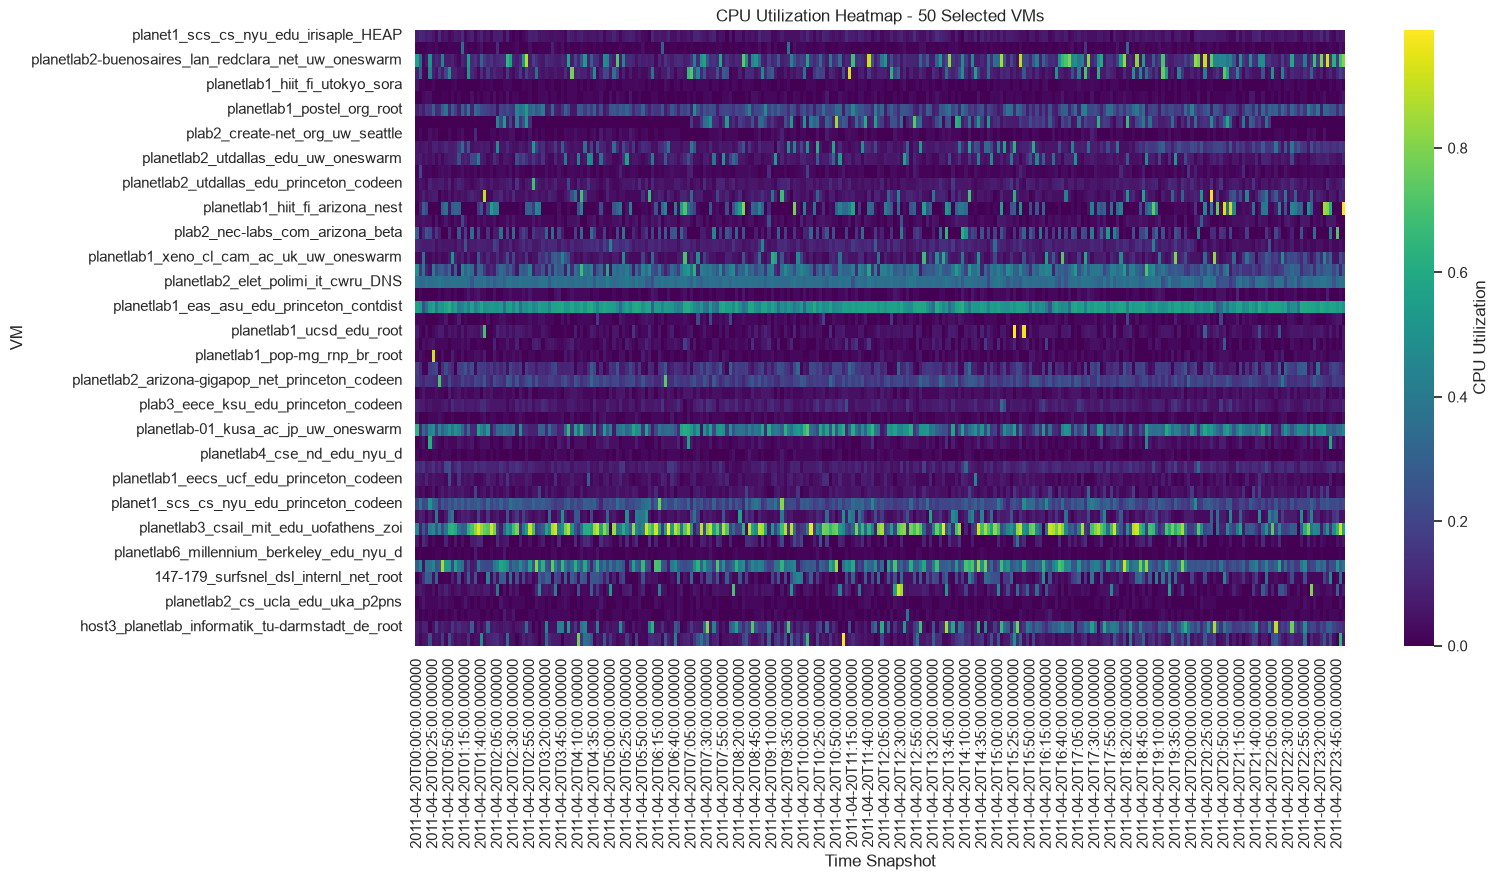

In [13]:
# ==========================================
# TEMPORAL CPU UTILIZATION
# ==========================================

plt.figure(figsize=(14, 6))

# Plot selected VMs
selected_vms = df_complete.columns[:10]

for vm in selected_vms:

    plt.plot(
        df_complete.index,
        df_complete[vm],
        label=vm,
        alpha=0.7
    )

plt.title("CPU Utilization Over Time - Selected VMs")
plt.xlabel("Time")
plt.ylabel("CPU Utilization")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

# ==========================================
# CPU UTILIZATION HEATMAP
# ==========================================

sample_vms = df_complete.sample(
    n=min(50, df_complete.shape[1]),
    axis=1,
    random_state=42
)

plt.figure(figsize=(15, 8))

sns.heatmap(
    sample_vms.T,
    cmap="viridis",
    cbar_kws={
        "label": "CPU Utilization"
    }
)

plt.title("CPU Utilization Heatmap - 50 Selected VMs")
plt.xlabel("Time Snapshot")
plt.ylabel("VM")

plt.show()

In [15]:

import numpy as np
import pandas as pd
import math

# Convert to numpy
U = df_complete.to_numpy(dtype=float)

# Jika data menggunakan skala 0-100, ubah ke 0-1
if np.nanmax(U) > 1:
    U = U / 100.0

# Validasi
print("Min utilization:", np.nanmin(U))
print("Max utilization:", np.nanmax(U))
print("Mean utilization:", np.nanmean(U))

# Total CPU demand setiap timestamp
# Asumsi setiap VM memiliki kapasitas 1 vCPU
vm_capacity = 1.0
D = np.sum(U * vm_capacity, axis=1)

print("\nTotal CPU demand:")
print("Mean:", D.mean())
print("Maximum:", D.max())
print("Minimum:", D.min())

# Skenario ukuran PM
rho = 0.80
pm_sizes = [8, 16, 32]

print("\nMinimum PM requirement (aggregate lower bound):")

for pm_capacity in pm_sizes:
    safe_capacity = rho * pm_capacity

    min_pm = math.ceil(D.max() / safe_capacity)

    print(
        f"PM {pm_capacity} vCPU | "
        f"Safe capacity: {safe_capacity} | "
        f"Minimum PM: {min_pm}"
    )


Min utilization: 0.0
Max utilization: 0.99
Mean utilization: 0.10431076556953857

Total CPU demand:
Mean: 107.75302083333345
Maximum: 123.88000000000018
Minimum: 93.3700000000002

Minimum PM requirement (aggregate lower bound):
PM 8 vCPU | Safe capacity: 6.4 | Minimum PM: 20
PM 16 vCPU | Safe capacity: 12.8 | Minimum PM: 10
PM 32 vCPU | Safe capacity: 25.6 | Minimum PM: 5
